## Etapa 1 — Obter a base no Google Colab

**Fonte:** UCI Machine Learning Repository — Online Retail II: https://archive.ics.uci.edu/dataset/502/online+retail+ii

**Pergunta de negócio:** É possível segmentar clientes com base na recência, frequência e valor monetário de suas compras? A ingestão e o tratamento das mais de um milhão de linhas demonstram o uso do Spark no pipeline de dados; o agrupamento final tem 5.878 clientes e, isoladamente, não requer processamento distribuído.


In [1]:
import requests
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

resposta = requests.get(url, timeout=180)
resposta.raise_for_status()

with open("online_retail_ii.zip", "wb") as arquivo:
    arquivo.write(resposta.content)

with zipfile.ZipFile("online_retail_ii.zip", "r") as zip_ref:
    zip_ref.extractall("dados")

print("Arquivos disponíveis:")
print(os.listdir("dados"))

Arquivos disponíveis:
['online_retail_II.xlsx']


## Etapa 2 — Carregar a base Excel no Google Colab

Instalar bibliotecas (sem upload manual de arquivos).


In [2]:
!pip -q install pyspark openpyxl
# O arquivo Excel é baixado automaticamente na Etapa 1.


Preparar os dados
Converter o Excel para CSV

In [3]:
import pandas as pd
import os

nome_arquivo = "dados/online_retail_II.xlsx"
assert os.path.exists(nome_arquivo), "Execute a Etapa 1 para baixar a base."
excel = pd.ExcelFile(nome_arquivo)
print("Planilhas encontradas:", excel.sheet_names)
for i, planilha in enumerate(excel.sheet_names):
    df_excel = pd.read_excel(nome_arquivo, sheet_name=planilha)
    nome_csv = f"online_retail_{i+1}.csv"
    df_excel.to_csv(nome_csv, index=False)
    print(f"{nome_csv}: {len(df_excel)} registros")


Planilhas encontradas: ['Year 2009-2010', 'Year 2010-2011']
online_retail_1.csv: 525461 registros
online_retail_2.csv: 541910 registros


Criar a sessão Spark e ler os CSVs

In [4]:

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Clusterizacao_Online_Retail_II")
    .getOrCreate()
)

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("online_retail_*.csv")
)

print("Total de registros:", df.count())

df.printSchema()

df.show(5, truncate=False)


Total de registros: 1067371
root
 |-- Invoice: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- Price: double (nullable = true)
 |-- Customer ID: double (nullable = true)
 |-- Country: string (nullable = true)

+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|Customer ID|Country       |
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|536365 |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |2010-12-01 08:26:00|2.55 |17850.0    |United Kingdom|
|536365 |71053    |WHITE METAL LANTERN                |6       |2010-12-01 08:26:00|3.39 |17850.0    |United Kingdom|
|536365 |84406B   |CREAM CUPID HEARTS COAT HANG

## Etapa 3 — Exploração e limpeza

Diagnóstico dos dados

In [5]:

from pyspark.sql import functions as F

print("Total original:", df.count())

# Verificar valores nulos
df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show()

# Verificar situações que exigem tratamento
df.select(
    F.sum(F.when(F.col("Customer ID").isNull(), 1)
          .otherwise(0)).alias("clientes_sem_id"),

    F.sum(F.when(F.col("Quantity") <= 0, 1)
          .otherwise(0)).alias("quantidades_invalidas"),

    F.sum(F.when(F.col("Price") <= 0, 1)
          .otherwise(0)).alias("precos_invalidos"),

    F.sum(F.when(
        F.upper(F.col("Invoice")).startswith("C"), 1
    ).otherwise(0)).alias("linhas_canceladas")
).show()

# Duplicatas exatas
print("Duplicatas exatas:",
      df.count() - df.dropDuplicates().count())

# Período dos dados
df.select(
    F.min("InvoiceDate").alias("data_inicial"),
    F.max("InvoiceDate").alias("data_final")
).show(truncate=False)


Total original: 1067371
+-------+---------+-----------+--------+-----------+-----+-----------+-------+
|Invoice|StockCode|Description|Quantity|InvoiceDate|Price|Customer ID|Country|
+-------+---------+-----------+--------+-----------+-----+-----------+-------+
|      0|        0|       4382|       0|          0|    0|     243007|      0|
+-------+---------+-----------+--------+-----------+-----+-----------+-------+

+---------------+---------------------+----------------+-----------------+
|clientes_sem_id|quantidades_invalidas|precos_invalidos|linhas_canceladas|
+---------------+---------------------+----------------+-----------------+
|         243007|                22950|            6207|            19494|
+---------------+---------------------+----------------+-----------------+

Duplicatas exatas: 34335
+-------------------+-------------------+
|data_inicial       |data_final         |
+-------------------+-------------------+
|2009-12-01 07:45:00|2011-12-09 12:50:00|
+----------

### Exploração e tratamento dos dados

A base Online Retail II apresentou inicialmente 1.067.371 registros, distribuídos em oito variáveis, abrangendo o período de dezembro de 2009 a dezembro de 2011.

Durante a preparação dos dados, foram aplicadas operações de limpeza utilizando funções do PySpark. Inicialmente, foram removidos 34.335 registros duplicados. Em seguida, foram excluídos 235.151 registros sem identificação do cliente, 18.390 registros com quantidades não positivas e 70 registros com preços não positivos.

As verificações posteriores de notas canceladas e datas ausentes não produziram exclusões adicionais, pois os registros correspondentes já haviam sido tratados nas etapas anteriores.

Ao final, foram excluídos 287.946 registros, correspondentes a aproximadamente 26,98% da base original, permanecendo 779.425 registros válidos, associados a 5.878 clientes distintos.

A limpeza teve como objetivo garantir que a construção dos indicadores de Recência, Frequência e Valor Monetário (RFM) utilizasse transações identificáveis e com valores positivos, proporcionando maior consistência à análise de clusterização.

In [6]:

from pyspark.sql import functions as F

# Base original
etapa0 = df
n0 = etapa0.count()

# 1. Remover duplicatas
etapa1 = etapa0.dropDuplicates()
n1 = etapa1.count()

# 2. Remover clientes sem identificação
etapa2 = etapa1.filter(
    F.col("Customer ID").isNotNull()
)
n2 = etapa2.count()

# 3. Remover quantidades não positivas
etapa3 = etapa2.filter(
    F.col("Quantity") > 0
)
n3 = etapa3.count()

# 4. Remover preços não positivos
etapa4 = etapa3.filter(
    F.col("Price") > 0
)
n4 = etapa4.count()

# 5. Remover notas canceladas
etapa5 = etapa4.filter(
    ~F.upper(F.col("Invoice")).startswith("C")
)
n5 = etapa5.count()

# 6. Remover datas nulas
etapa6 = etapa5.filter(
    F.col("InvoiceDate").isNotNull()
)
n6 = etapa6.count()

# Resumo
resultados = [
    ("Duplicatas", n0 - n1),
    ("Clientes sem ID", n1 - n2),
    ("Quantidade inválida", n2 - n3),
    ("Preço inválido", n3 - n4),
    ("Notas canceladas", n4 - n5),
    ("Datas nulas", n5 - n6)
]

print("RESUMO DAS EXCLUSÕES")
print("-" * 45)

for motivo, quantidade in resultados:
    print(f"{motivo:25s}: {quantidade:>8,}")

print("-" * 45)
print(f"Total excluído: {n0 - n6:,}")
print(f"Total restante: {n6:,}")


RESUMO DAS EXCLUSÕES
---------------------------------------------
Duplicatas               :   34,335
Clientes sem ID          :  235,151
Quantidade inválida      :   18,390
Preço inválido           :       70
Notas canceladas         :        0
Datas nulas              :        0
---------------------------------------------
Total excluído: 287,946
Total restante: 779,425


Aplicar a limpeza com PySpark

In [7]:

from pyspark.sql import functions as F

# Guardar o total original
total_original = df.count()

# Remover duplicatas exatas
df_limpo = df.dropDuplicates()

# Manter compras válidas e clientes identificados
df_limpo = df_limpo.filter(
    (F.col("Customer ID").isNotNull()) &
    (F.col("Quantity") > 0) &
    (F.col("Price") > 0) &
    (~F.upper(F.col("Invoice")).startswith("C")) &
    (F.col("InvoiceDate").isNotNull())
)

# Converter o identificador para inteiro
df_limpo = df_limpo.withColumn(
    "CustomerID",
    F.col("Customer ID").cast("long")
)

# Calcular o valor de cada linha da compra
df_limpo = df_limpo.withColumn(
    "ValorTotal",
    F.col("Quantity") * F.col("Price")
)

# Resultados da limpeza
total_limpo = df_limpo.count()

print("Total original:", total_original)
print("Total após limpeza:", total_limpo)
print("Registros excluídos:",
      total_original - total_limpo)

print("Clientes distintos:",
      df_limpo.select("CustomerID").distinct().count())

print("Notas fiscais distintas:",
      df_limpo.select("Invoice").distinct().count())

df_limpo.select(
    "CustomerID",
    "Invoice",
    "InvoiceDate",
    "Quantity",
    "Price",
    "ValorTotal"
).show(5, truncate=False)


Total original: 1067371
Total após limpeza: 779425
Registros excluídos: 287946
Clientes distintos: 5878
Notas fiscais distintas: 36969
+----------+-------+-------------------+--------+-----+------------------+
|CustomerID|Invoice|InvoiceDate        |Quantity|Price|ValorTotal        |
+----------+-------+-------------------+--------+-----+------------------+
|12583     |536370 |2010-12-01 08:45:00|24      |0.65 |15.600000000000001|
|17850     |536375 |2010-12-01 09:32:00|6       |1.06 |6.36              |
|15311     |536381 |2010-12-01 09:41:00|1       |0.85 |0.85              |
|12431     |536389 |2010-12-01 10:03:00|2       |8.5  |17.0              |
|15862     |536401 |2010-12-01 11:21:00|1       |1.25 |1.25              |
+----------+-------+-------------------+--------+-----+------------------+
only showing top 5 rows


## Etapa 4 — Construção dos indicadores RFM

Criar a tabela RFM no PySpark

RFM significa:
- R — Recência: quantos dias se passaram desde a última compra.
- F — Frequência: quantas compras diferentes o cliente realizou.
- M — Monetário: quanto o cliente gastou no período.


In [8]:

from pyspark.sql import functions as F

# Data de referência: dia seguinte à última compra
data_referencia = df_limpo.select(
    F.date_add(
        F.max("InvoiceDate"), 1
    ).alias("referencia")
).first()["referencia"]

print("Data de referência:", data_referencia)

# Criar chave de fatura considerando o ano
df_rfm_base = df_limpo.withColumn(
    "ChaveFatura",
    F.concat_ws(
        "_",
        F.year("InvoiceDate").cast("string"),
        F.col("Invoice")
    )
)

# Agregar as transações por cliente
df_rfm = df_rfm_base.groupBy("CustomerID").agg(
    F.datediff(
        F.lit(data_referencia),
        F.max("InvoiceDate")
    ).alias("Recencia"),

    F.countDistinct("ChaveFatura").alias("Frequencia"),

    F.round(
        F.sum("ValorTotal"), 2
    ).alias("Monetario")
)

print("Quantidade de clientes:", df_rfm.count())

df_rfm.show(10, truncate=False)


Data de referência: 2011-12-10
Quantidade de clientes: 5878
+----------+--------+----------+---------+
|CustomerID|Recencia|Frequencia|Monetario|
+----------+--------+----------+---------+
|15194     |4       |28        |12021.53 |
|15663     |107     |1         |138.14   |
|13460     |30      |2         |183.44   |
|13723     |218     |6         |1194.08  |
|13098     |2       |28        |28882.44 |
|17979     |36      |4         |732.41   |
|16742     |47      |14        |2799.87  |
|15237     |2       |4         |1412.32  |
|14846     |428     |1         |437.4    |
|17499     |290     |2         |1341.39  |
+----------+--------+----------+---------+
only showing top 10 rows


Verificar as estatísticas descritivas

In [9]:

df_rfm.select(
    "Recencia",
    "Frequencia",
    "Monetario"
).describe().show()


+-------+------------------+------------------+------------------+
|summary|          Recencia|        Frequencia|         Monetario|
+-------+------------------+------------------+------------------+
|  count|              5878|              5878|              5878|
|   mean|201.86679142565498| 6.289384144266758|2955.9040915277333|
| stddev|209.35396089461534|13.009405882310157| 14440.85268639682|
|    min|                 1|                 1|              2.95|
|    max|               739|               398|         580987.04|
+-------+------------------+------------------+------------------+



1. Análise dos indicadores RFM
Indicador	Média	Desvio padrão	Mínimo	Máximo
Recência (dias)	201,87	209,35	1	739
Frequência (compras)	6,29	13,01	1	398
Monetário	2.955,90	14.440,85	2,95	580.987,04

Podemos observar três situações:

Recência: existem clientes que compraram há apenas um dia e outros cuja última compra ocorreu há 739 dias.

Frequência: embora a média seja de aproximadamente seis compras, há clientes com até 398 compras.

Monetário: a média é de 2.955,90, mas o valor máximo chega a 580.987,04. O desvio padrão é muito maior que a média.

Isso sugere distribuições bastante assimétricas, especialmente para frequência e valor monetário.

Se aplicarmos o K-Means diretamente sobre esses valores, a variável monetária poderá dominar as distâncias entre os clientes.

Por isso, vamos utilizar duas transformações:
1. Logarítmica (log1p) para reduzir a influência de valores extremos.
2. Padronização (StandardScaler) para colocar as três variáveis em escalas comparáveis.

## Etapa 5 — Engenharia de atributos e Pipeline

Criar as variáveis transformadas

In [10]:

from pyspark.sql import functions as F

# Transformação logarítmica dos indicadores RFM
df_rfm_log = (
    df_rfm
    .withColumn(
        "Recencia_log",
        F.log1p(F.col("Recencia"))
    )
    .withColumn(
        "Frequencia_log",
        F.log1p(F.col("Frequencia"))
    )
    .withColumn(
        "Monetario_log",
        F.log1p(F.col("Monetario"))
    )
)

df_rfm_log.select(
    "CustomerID",
    "Recencia_log",
    "Frequencia_log",
    "Monetario_log"
).show(10, truncate=False)


+----------+------------------+------------------+------------------+
|CustomerID|Recencia_log      |Frequencia_log    |Monetario_log     |
+----------+------------------+------------------+------------------+
|15194     |1.6094379124341003|3.367295829986474 |9.394537668469978 |
|15663     |4.68213122712422  |0.6931471805599453|4.935480620495495 |
|13460     |3.4339872044851463|1.0986122886681096|5.217324207338505 |
|13723     |5.389071729816501 |1.9459101490553132|7.085968407731548 |
|13098     |1.0986122886681096|3.367295829986474 |10.271023699486712|
|17979     |3.6109179126442243|1.6094379124341003|6.597704890668348 |
|16742     |3.8712010109078907|2.70805020110221  |7.937685362187323 |
|15237     |1.0986122886681096|1.6094379124341003|7.253696825551129 |
|14846     |6.061456918928017 |0.6931471805599453|6.083131735633806 |
|17499     |5.673323267171493 |1.0986122886681096|7.202206886340738 |
+----------+------------------+------------------+------------------+
only showing top 10 

Criar o Pipeline de preparação

In [11]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Combinar os atributos em um vetor
assembler = VectorAssembler(
    inputCols=[
        "Recencia_log",
        "Frequencia_log",
        "Monetario_log"
    ],
    outputCol="features_raw"
)

# Padronizar os atributos
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

# Construir o Pipeline
pipeline_preparacao = Pipeline(
    stages=[assembler, scaler]
)

# Ajustar o Pipeline aos dados
modelo_preparacao = pipeline_preparacao.fit(df_rfm_log)

# Aplicar as transformações
df_features = modelo_preparacao.transform(df_rfm_log)

df_features.select(
    "CustomerID",
    "features"
).show(10, truncate=False)


+----------+-------------------------------------------------------------+
|CustomerID|features                                                     |
+----------+-------------------------------------------------------------+
|15194     |[-1.8711206383509627,2.245616971330646,1.8603999676246432]   |
|15663     |[0.13597508197869534,-1.0580559338734123,-1.358005369130417] |
|13460     |[-0.6793176497160628,-0.557139841587429,-1.1545796460982853] |
|13723     |[0.5977514820827421,0.4896213340109668,0.19414821325333126]  |
|13098     |[-2.2047940050985475,2.245616971330646,2.4930196648982856]   |
|17979     |[-0.5637457944179056,0.07393980048167283,-0.1582648400339815]|
|16742     |[-0.3937278202512147,1.4311776085501924,0.8088903800687126]  |
|15237     |[-2.2047940050985475,0.07393980048167283,0.3152092423516769] |
|14846     |[1.0369562113757054,-1.0580559338734123,-0.5296673519319491] |
|17499     |[0.7834257377576425,-0.557139841587429,0.2780454444094207]   |
+----------+-------------

## Etapa 6 — Treinar K-Means e escolher o número de clusters

Executar os modelos

In [12]:

from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Evitar recalcular a preparação em cada teste
df_features = df_features.cache()
df_features.count()

# Avaliador de clusterização
avaliador = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

resultados_k = []
modelos_k = {}

for k in range(2, 9):

    print(f"Treinando K-Means com k={k}...")

    kmeans = KMeans(
        k=k,
        seed=42,
        maxIter=50,
        featuresCol="features",
        predictionCol="prediction"
    )

    modelo = kmeans.fit(df_features)
    previsoes = modelo.transform(df_features)

    silhueta = avaliador.evaluate(previsoes)
    inercia = modelo.summary.trainingCost

    resultados_k.append((k, silhueta, inercia))
    modelos_k[k] = modelo

    print(f"  Silhueta: {silhueta:.4f}")
    print(f"  Inércia: {inercia:.2f}")
    print("-" * 40)

print("Treinamento concluído!")


Treinando K-Means com k=2...
  Silhueta: 0.6268
  Inércia: 8575.58
----------------------------------------
Treinando K-Means com k=3...
  Silhueta: 0.5048
  Inércia: 6335.56
----------------------------------------
Treinando K-Means com k=4...
  Silhueta: 0.5317
  Inércia: 4894.57
----------------------------------------
Treinando K-Means com k=5...
  Silhueta: 0.5093
  Inércia: 4068.48
----------------------------------------
Treinando K-Means com k=6...
  Silhueta: 0.4928
  Inércia: 3536.31
----------------------------------------
Treinando K-Means com k=7...
  Silhueta: 0.4842
  Inércia: 3185.84
----------------------------------------
Treinando K-Means com k=8...
  Silhueta: 0.4335
  Inércia: 2891.14
----------------------------------------
Treinamento concluído!


Construir os gráficos

,k,Silhueta,Inercia
0,2,0.626844,8575.582845
1,3,0.504755,6335.557038
2,4,0.531696,4894.568157
3,5,0.509305,4068.482218
4,6,0.492750,3536.306642
5,7,0.484196,3185.839192
6,8,0.433535,2891.139462


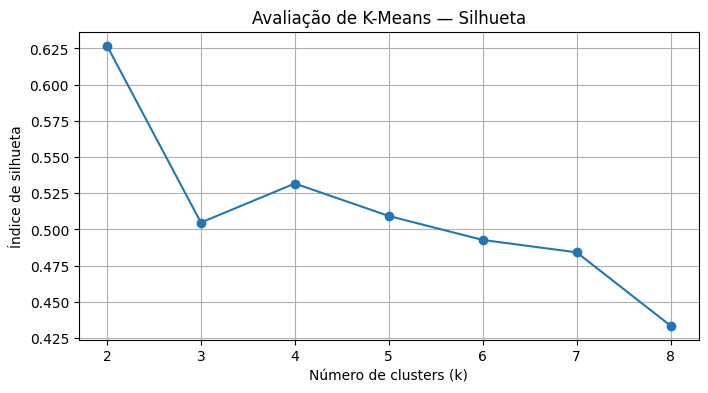

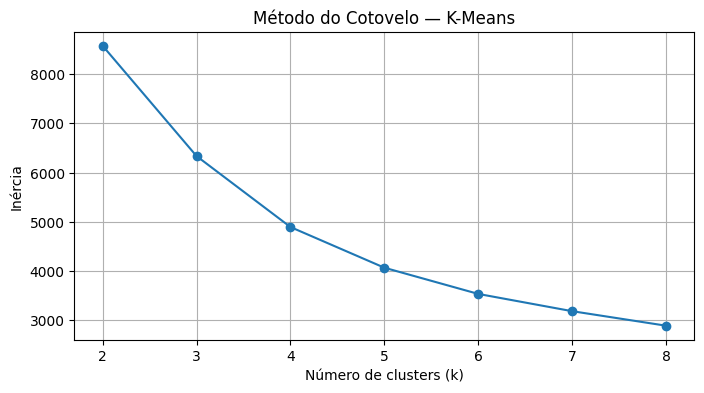

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

df_resultados = pd.DataFrame(
    resultados_k,
    columns=["k", "Silhueta", "Inercia"]
)

display(df_resultados)

# Gráfico de silhueta
plt.figure(figsize=(8, 4))
plt.plot(
    df_resultados["k"],
    df_resultados["Silhueta"],
    marker="o"
)
plt.xlabel("Número de clusters (k)")
plt.ylabel("Índice de silhueta")
plt.title("Avaliação de K-Means — Silhueta")
plt.grid(True)
plt.show()

# Gráfico do cotovelo
plt.figure(figsize=(8, 4))
plt.plot(
    df_resultados["k"],
    df_resultados["Inercia"],
    marker="o"
)
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo — K-Means")
plt.grid(True)
plt.show()


Etapa 7 — Interpretar os clusters

In [14]:

from pyspark.sql import functions as F

for k in [2, 4]:
    print(f"\n{'=' * 55}")
    print(f"PERFIL DOS CLIENTES — K = {k}")
    print("=" * 55)

    modelo = modelos_k[k]
    previsoes = modelo.transform(df_features)

    perfil = (
        previsoes
        .groupBy("prediction")
        .agg(
            F.count("*").alias("Clientes"),
            F.round(F.avg("Recencia"), 2).alias("Recencia_media"),
            F.round(F.avg("Frequencia"), 2).alias("Frequencia_media"),
            F.round(F.avg("Monetario"), 2).alias("Monetario_medio"),
            F.round(
                F.expr("percentile_approx(Monetario, 0.5)"), 2
            ).alias("Monetario_mediano")
        )
        .withColumn(
            "Percentual",
            F.round(F.col("Clientes") * 100 / 5878, 2)
        )
        .orderBy("prediction")
    )

    perfil.show(truncate=False)



PERFIL DOS CLIENTES — K = 2
+----------+--------+--------------+----------------+---------------+-----------------+----------+
|prediction|Clientes|Recencia_media|Frequencia_media|Monetario_medio|Monetario_mediano|Percentual|
+----------+--------+--------------+----------------+---------------+-----------------+----------+
|0         |3539    |301.54        |2.09            |610.73         |413.08           |60.21     |
|1         |2339    |51.05         |12.64           |6504.25        |2839.62          |39.79     |
+----------+--------+--------------+----------------+---------------+-----------------+----------+


PERFIL DOS CLIENTES — K = 4
+----------+--------+--------------+----------------+---------------+-----------------+----------+
|prediction|Clientes|Recencia_media|Frequencia_media|Monetario_medio|Monetario_mediano|Percentual|
+----------+--------+--------------+----------------+---------------+-----------------+----------+
|0         |1454    |231.06        |5.03          

Interpretação dos quatro clusters
------------------
33,36%
Cluster 1
Clientes inativos ou de baixo engajamento

1.961 clientes, com recência média de 397,55 dias, frequência de apenas 1,38 compras e gasto médio de 316,17.

São clientes com histórico de poucas compras e longo período sem comprar.
-----------------



24,74%
Cluster 0
Clientes em risco de afastamento

1.454 clientes, com recência média de 231,06 dias, frequência de 5,03 compras e gasto médio de 1.945,21.

Apresentam histórico de compras mais consistente, mas estão afastados há bastante tempo.



21,47%
Cluster 2
Clientes recentes de baixa frequência

1.262 clientes, com recência média de 29,20 dias, frequência de 3,04 compras e gasto médio de 854,07.

Compraram recentemente, mas ainda apresentam frequência e valor de compras relativamente baixos.



20,43%
Cluster 3
Clientes de alto valor e alta frequência

1.201 clientes, com recência média de 28,44 dias, frequência de 19,24 compras e gasto médio de 10.698,26.

São os clientes mais ativos e com maior gasto, constituindo um grupo importante para ações de fidelização.

## Etapa 8 — Selecionar e salvar o modelo final

In [15]:
from pyspark.ml import Pipeline

# Salvar o Pipeline completo: VectorAssembler + StandardScaler + KMeans.
# Reutilizamos o modelo já treinado para preservar os clusters avaliados.
k_final = 4
modelo_final = modelos_k[k_final]
modelo_pipeline_completo = Pipeline(stages=[assembler, scaler, KMeans(
    k=k_final, seed=42, maxIter=50, featuresCol="features", predictionCol="prediction"
)]).fit(df_rfm_log)

df_clusters = modelo_final.transform(df_features)
df_clusters.select("CustomerID", "Recencia", "Frequencia", "Monetario", "prediction").show(15, truncate=False)

modelo_pipeline_completo.write().overwrite().save("modelo_pipeline_kmeans_rfm")
print("Pipeline completo salvo com sucesso!")
print("Clusters:", k_final)


+----------+--------+----------+---------+----------+
|CustomerID|Recencia|Frequencia|Monetario|prediction|
+----------+--------+----------+---------+----------+
|15194     |4       |28        |12021.53 |3         |
|15663     |107     |1         |138.14   |1         |
|13460     |30      |2         |183.44   |2         |
|13723     |218     |6         |1194.08  |0         |
|13098     |2       |28        |28882.44 |3         |
|17979     |36      |4         |732.41   |2         |
|16742     |47      |14        |2799.87  |3         |
|15237     |2       |4         |1412.32  |2         |
|14846     |428     |1         |437.4    |1         |
|17499     |290     |2         |1341.39  |0         |
|15057     |276     |5         |3255.96  |0         |
|12568     |645     |1         |70.0     |1         |
|18147     |46      |2         |179.34   |2         |
|15322     |86      |2         |1390.86  |0         |
|17703     |36      |4         |1094.84  |2         |
+----------+--------+-------

Verificar se o modelo pode ser recuperado

In [17]:
from pyspark.ml import PipelineModel
pipeline_carregado = PipelineModel.load("modelo_pipeline_kmeans_rfm")
print("Pipeline completo carregado com sucesso!")
print("Clusters:", len(pipeline_carregado.stages[-1].clusterCenters()))


Pipeline completo carregado com sucesso!
Clusters: 4


## Conclusão e limitações


O objetivo deste trabalho foi identificar diferentes perfis de clientes de um comércio eletrônico utilizando técnicas de Clusterização com o algoritmo K-Means, implementado no Apache Spark ML.

Inicialmente, utilizamos a base Online Retail II, contendo 1.067.371 registros de transações comerciais. Após a limpeza dos dados, permaneceram 779.425 registros válidos, correspondentes a 5.878 clientes distintos.

Para analisar o comportamento desses clientes, utilizamos três indicadores: Recência (tempo desde a última compra), Frequência (quantidade de compras realizadas) e Monetário (valor total gasto).

Foram testados modelos K-Means com diferentes quantidades de clusters, de 2 a 8. O modelo com dois clusters apresentou o melhor índice de silhueta (0,6268), indicando maior separação dos grupos segundo essa métrica.

Entretanto, optamos pelo modelo com quatro clusters, que apresentou silhueta de 0,5317, por permitir uma interpretação mais detalhada dos comportamentos de compra.

Com quatro clusters, identificamos os seguintes perfis:

- **Cluster 0:** clientes ocasionais ou em risco de afastamento, com histórico de compras, mas que estão há bastante tempo sem comprar.
- **Cluster 1:** clientes pouco engajados ou inativos, com baixa frequência de compras e longo período de ausência.
- **Cluster 2:** clientes que compraram recentemente, mas apresentam menor frequência e valor de consumo.
- **Cluster 3:** clientes de alto valor, que compram frequentemente, gastam mais e realizaram compras recentes.

Esses resultados demonstram que a Clusterização pode ajudar uma empresa a compreender melhor seus clientes e desenvolver estratégias diferenciadas de relacionamento, retenção e fidelização.

### Limitações

O trabalho apresenta algumas limitações. Foram excluídos registros sem identificação do cliente, compras canceladas, devoluções e registros duplicados. Algumas linhas duplicadas podem representar operações legítimas, o que constitui uma limitação do tratamento adotado.

Além disso, os dados são históricos, abrangendo o período de 2009 a 2011, e os resultados dependem das variáveis e transformações utilizadas no K-Means.

Embora o processamento inicial tenha envolvido mais de um milhão de transações com PySpark, a Clusterização foi realizada sobre 5.878 perfis de clientes, obtidos após a agregação dos dados.

Como melhoria futura, seria interessante testar outros algoritmos de Clusterização e verificar se os grupos identificados permanecem semelhantes com diferentes configurações e períodos de análise.

Concluímos que o Apache Spark permitiu realizar as etapas de preparação e análise dos dados, enquanto o Spark ML possibilitou identificar quatro segmentos de clientes com características comerciais distintas.
